# 02-STC内存、任务堆栈与任务切换原理

> 任务函数的代码仍在程序存储器中。每个任务准备自己的栈和保存的 SP；切换到另一份栈后，返回指令从那份栈取出地址，CPU 因而进入或继续另一个任务。

这是《自己动手写嵌入式操作系统》五篇笔记中的第 02 篇。阅读前建议先掌握第 01 篇的任务、上下文和调度概念。


## 1. 本篇范围与已核对资料

| 视频 | 目录标题 | 本篇重点 |
|---|---|---|
| 09 | stc单片机的内存结构 | 程序空间、内部 RAM、SFR 与访问方式 |
| 10 | 程序执行顺序切换的原理 | PC、跳转、调用和返回 |
| 11 | 声明两个任务的堆栈指针和任务堆栈 | 保存 SP 的数组与实际栈空间 |
| 12 | 定义操作系统的loadtask函数 | 给任务构造初始返回地址 |
| 13 | 通过修改SP，来修改调用的函数 | 换栈后由返回指令改变执行位置 |

**核对范围：**已核对视频目录、配套讲义第 **14—16 页**，并读取网盘 `代码/os_demo.zip` 内的 `os_demo/main.c`、编译清单 `Listings/main.lst`、链接表 `Listings/project.m51`、工程配置及已有的 `Objects/project.hex`。

视频未逐段观看或转录。本篇区分讲义原图、配套源码、包内已有编译结果，以及用于解释的补充原理；没有在当前环境重新编译或进行硬件运行验证。

**命名说明：**视频 12 标题写 `loadtask`，配套源码中的实际函数名是 **`task_load`**。正文分析源码时使用后者。压缩包是含调度和计时的综合示例，不能把它当作每个视频各阶段的历史代码。


## 2. 从上下文概念落到三个具体对象

第 01 篇说，任务切换必须让任务以后能接着运行。本篇把这个要求落到：

| 对象 | 保存什么 | 在配套源码中的表达 |
|---|---|---|
| 任务入口 | 第一次开始执行的代码地址 | `task0`、`task1` 的函数地址 |
| 任务栈 | 返回地址和按约定压入的数据 | `task_stack[tid]` |
| 保存的 SP | 这份栈当前的顶部位置 | `task_sp[tid]` |

```text
程序空间：task0 的代码、task1 的代码
数据空间：task0 的栈、task1 的栈、各自保存的 SP
CPU：当前只使用一组硬件 SP 与相关执行状态
```

不要混淆“任务栈”和“存放 SP 的数组”：栈是保存多个字节的区域，SP 是指出顶部位置的一个值。

**补充理解：**不同 CPU 的栈方向和返回机制可能不同。下文采用经典 8051 兼容内核的基本规则，并结合本工程的 C51 编译结果说明。


## 3. 8051 的内存不是一条可以随意互换的地址线

讲义第 14 页列出内部数据区域与 SFR，第 15 页区分 RAM 和程序存储器。先按用途理解：

| 空间 | 主要用途 | 对本篇的意义 |
|---|---|---|
| CODE 程序空间 | 指令和程序常量 | 任务函数入口是代码地址 |
| 内部数据 RAM | 运行数据、寄存器组和硬件栈等 | 任务栈必须与硬件栈访问方式匹配 |
| SFR | SP、PSW、端口和定时器等控制寄存器 | 改写 SP 通过它对应的寄存器完成 |
| XDATA | 扩展数据空间 | 与内部硬件栈不是同一种访问空间 |

**补充理解：**不同空间中可以出现相同的数值地址。例如 CODE 的 `0x0015` 和内部 RAM 的 `0x15` 并不因此成为同一个字节。处理器采用的访问方式决定访问哪一种空间。

工程配置把目标设为 **STC8H8K64U Series**；配套链接表使用 `RAMSIZE(256)` 和 SMALL 内存模型。不同 STC 型号的 RAM、Flash 和扩展数据能力不同，本篇不把某个工程的容量推广到全部型号。


## 4. 内部 RAM、寄存器组与 SFR

讲义第 14 页提供下面这张入门图：

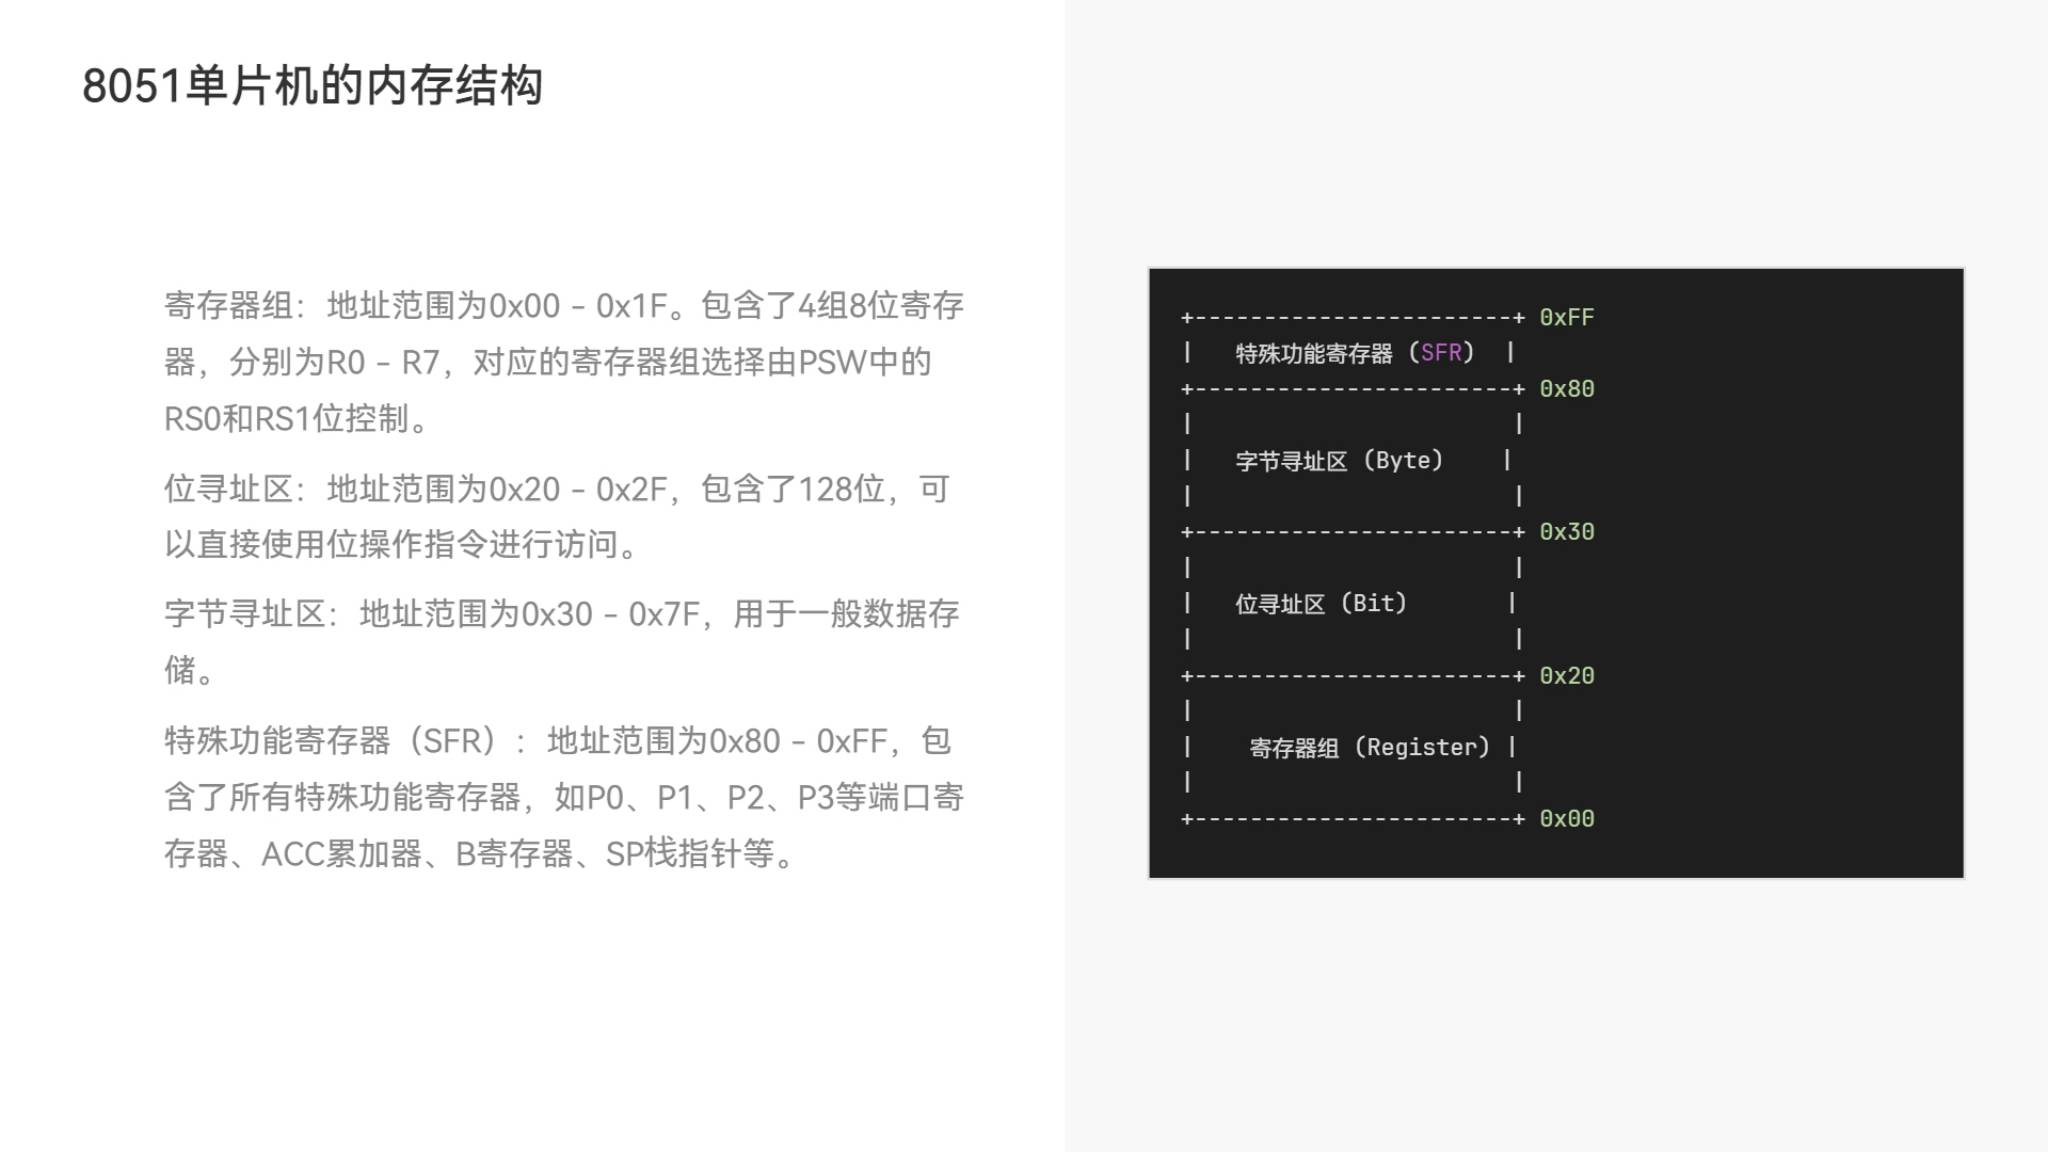

*来源：配套讲义第 14 页，原始在线预览图。下表补充访问方式，避免把图读成一个统一 RAM 区域。*

| 范围 | 经典布局中的用途 | 说明 |
|---|---|---|
| `0x00—0x1F` | 4 组 R0—R7 | 当前寄存器组由 PSW 中的 RS1、RS0 选择 |
| `0x20—0x2F` | 位寻址 RAM 区域 | 16 字节，共 128 位 |
| `0x30—0x7F` | 常用通用 RAM 区域 | 与前两段一起属于低 128 字节 RAM |
| `0x80—0xFF`，直接寻址 | SFR 地址区 | 并非每个地址都有已实现的 SFR |
| `0x80—0xFF`，间接寻址 | 高 128 字节内部 RAM，若器件实现 | 与同号的 SFR 地址有区别 |

**补充理解：**经典 8051 基础型号只有低 128 字节内部 RAM；8052 类及许多增强型号实现了高 128 字节。应按实际器件手册判断。

例如，在实现高 RAM 的器件上，直接访问 `0x81` 可以访问 SP；用 R0/R1 间接访问内部 RAM 地址 `0x81`，访问的是 RAM，而不是 SP。硬件栈访问内部 RAM，不能把“SP 超过 `0x7F`”简单理解为改写端口寄存器。

寄存器组和位寻址 RAM 也有内存占用关系：使用某组寄存器、某些位变量或数组时，必须由工程布局确保不互相覆盖。


## 5. Flash 中的代码与 RAM 中的任务栈

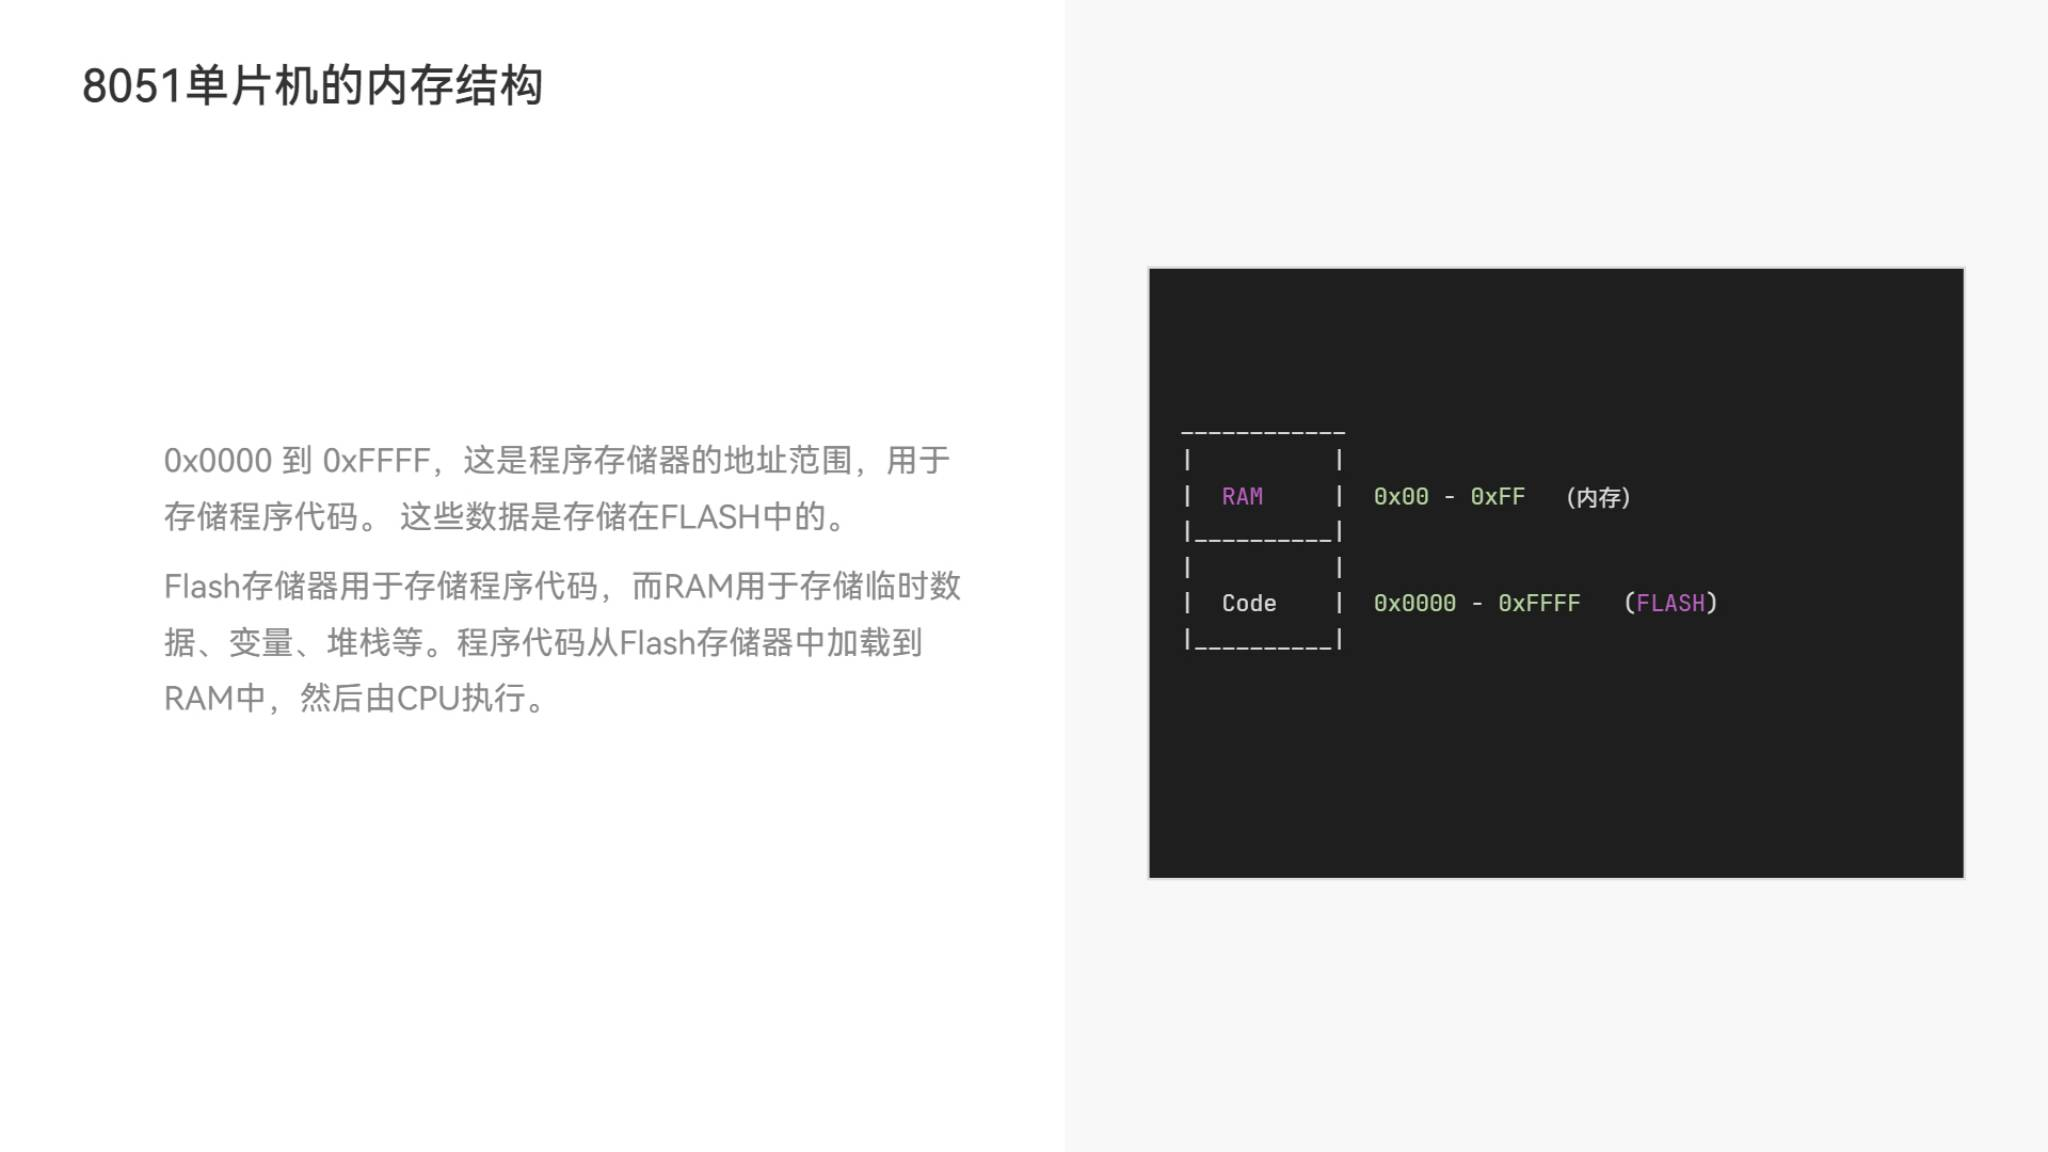

*来源：配套讲义第 15 页。图用于区分代码与数据，下列说明修正容易误读的表述。*

**补充校正：**讲义写到“程序代码从 Flash 加载到 RAM 后由 CPU 执行”。对这里讨论的经典 8051/STC 模型，CPU 通常从程序空间取指，**不需要先把全部指令复制到数据 RAM**。启动代码可能把变量初值从程序空间复制到 RAM，那是数据初始化，不能与代码搬运混为一谈。

讲义中的 `0x0000—0xFFFF` 表示经典 16 位 CODE 地址空间的范围，不证明每个型号都实现了完整 64 KiB 片内 Flash。图里的 RAM `0x00—0xFF` 也不能包含 SFR 的全部访问语义，更不能代表所有扩展 RAM。

```text
task0 的机器指令：仍在程序空间
task0 的入口地址：可以拆成字节，作为数据放到 RAM 中
task0 的任务栈：保存这些地址字节及后续返回信息
```

因此，源码里的 `task_load` 主要是在**准备任务栈**，不是把函数的全部机器码搬进栈数组。


## 6. PC 与 SP：一个指向指令，一个指向栈顶

以下为**补充理解**。

| 名称 | 含义 | 在本模型中的作用 |
|---|---|---|
| PC | 程序计数器 | 表示取指/执行位置，跳转、调用和返回会影响它 |
| SP | 堆栈指针 | 指向当前已使用栈区域的顶部 |

经典 8051 的 PC 为 16 位，SP 为 8 位。配套代码把任务入口按 16 位地址处理，把保存的 SP 放在 `unsigned char` 中，这是该工程的具体模型。

```text
PC = 代码位置
SP = 栈顶部位置
```

SP 中不保存“下一条指令的地址”。仅写 SP 不会立即把 PC 改成相同数值；后续执行 `RET` 时，从 SP 指定的栈取出返回地址，PC 才会按返回机制变化。


## 7. 栈怎样增长：先增加 SP，再写入

以下为**补充例子**。经典 8051 的硬件栈向较高地址增长：

```text
压入一个字节：SP ← SP + 1；内部 RAM[SP] ← 字节
弹出一个字节：读出内部 RAM[SP]；SP ← SP - 1
```

假设给某个栈预留的首地址是 `0x40`，空栈时可以令 `SP=0x3F`：

| 动作 | SP | 内存变化 |
|---|---|---|
| 空栈 | `0x3F` | 尚未使用预留区域 |
| 压入 `0xAA` | `0x40` | `[0x40]=0xAA` |
| 压入 `0xBB` | `0x41` | `[0x41]=0xBB` |
| 弹出 | `0x40` | 得到 `0xBB` |
| 再弹出 | `0x3F` | 得到 `0xAA` |

这体现后进先出。弹出后原内存字节可能还在，但逻辑上已不属于当前有效栈内容；不能通过“那里还有一个旧值”判断栈仍在使用它。

重要区别：**空栈 SP 是首地址减一；含两个初始返回地址字节的栈，SP 是首地址加一。** 两种状态不能用同一个初值。


## 8. CALL、RET 与地址字节顺序

以下为**补充理解**，采用经典 8051 的普通调用/返回规则。

一次 CALL 除了转到被调用代码，还保存调用后应继续执行的地址。保存两字节返回地址时，低字节先压入，高字节后压入；RET 从顶部取回高字节，再取回低字节，恢复 PC。

假设调用后应继续执行的地址是 `0x1234`，调用前 `SP=0x3F`：

```text
CALL 保存后：
地址 0x40：0x34，返回地址低字节
地址 0x41：0x12，返回地址高字节 ← SP

RET 后：PC=0x1234，SP=0x3F
```

CALL 保存的是**调用后的继续位置**，不是被调用函数的入口。LCALL 是 3 字节指令，正常返回位置在它之后；ACALL 的长度和寻址形式不同。

RET 不会自动恢复全部通用寄存器。中断入口、编译器生成的保存代码和 RETI 还涉及其他规则；**不能把 RET 与 RETI 当作可任意替换的同义指令**。本篇先关注普通返回地址链。


## 9. 怎样改变执行顺序？

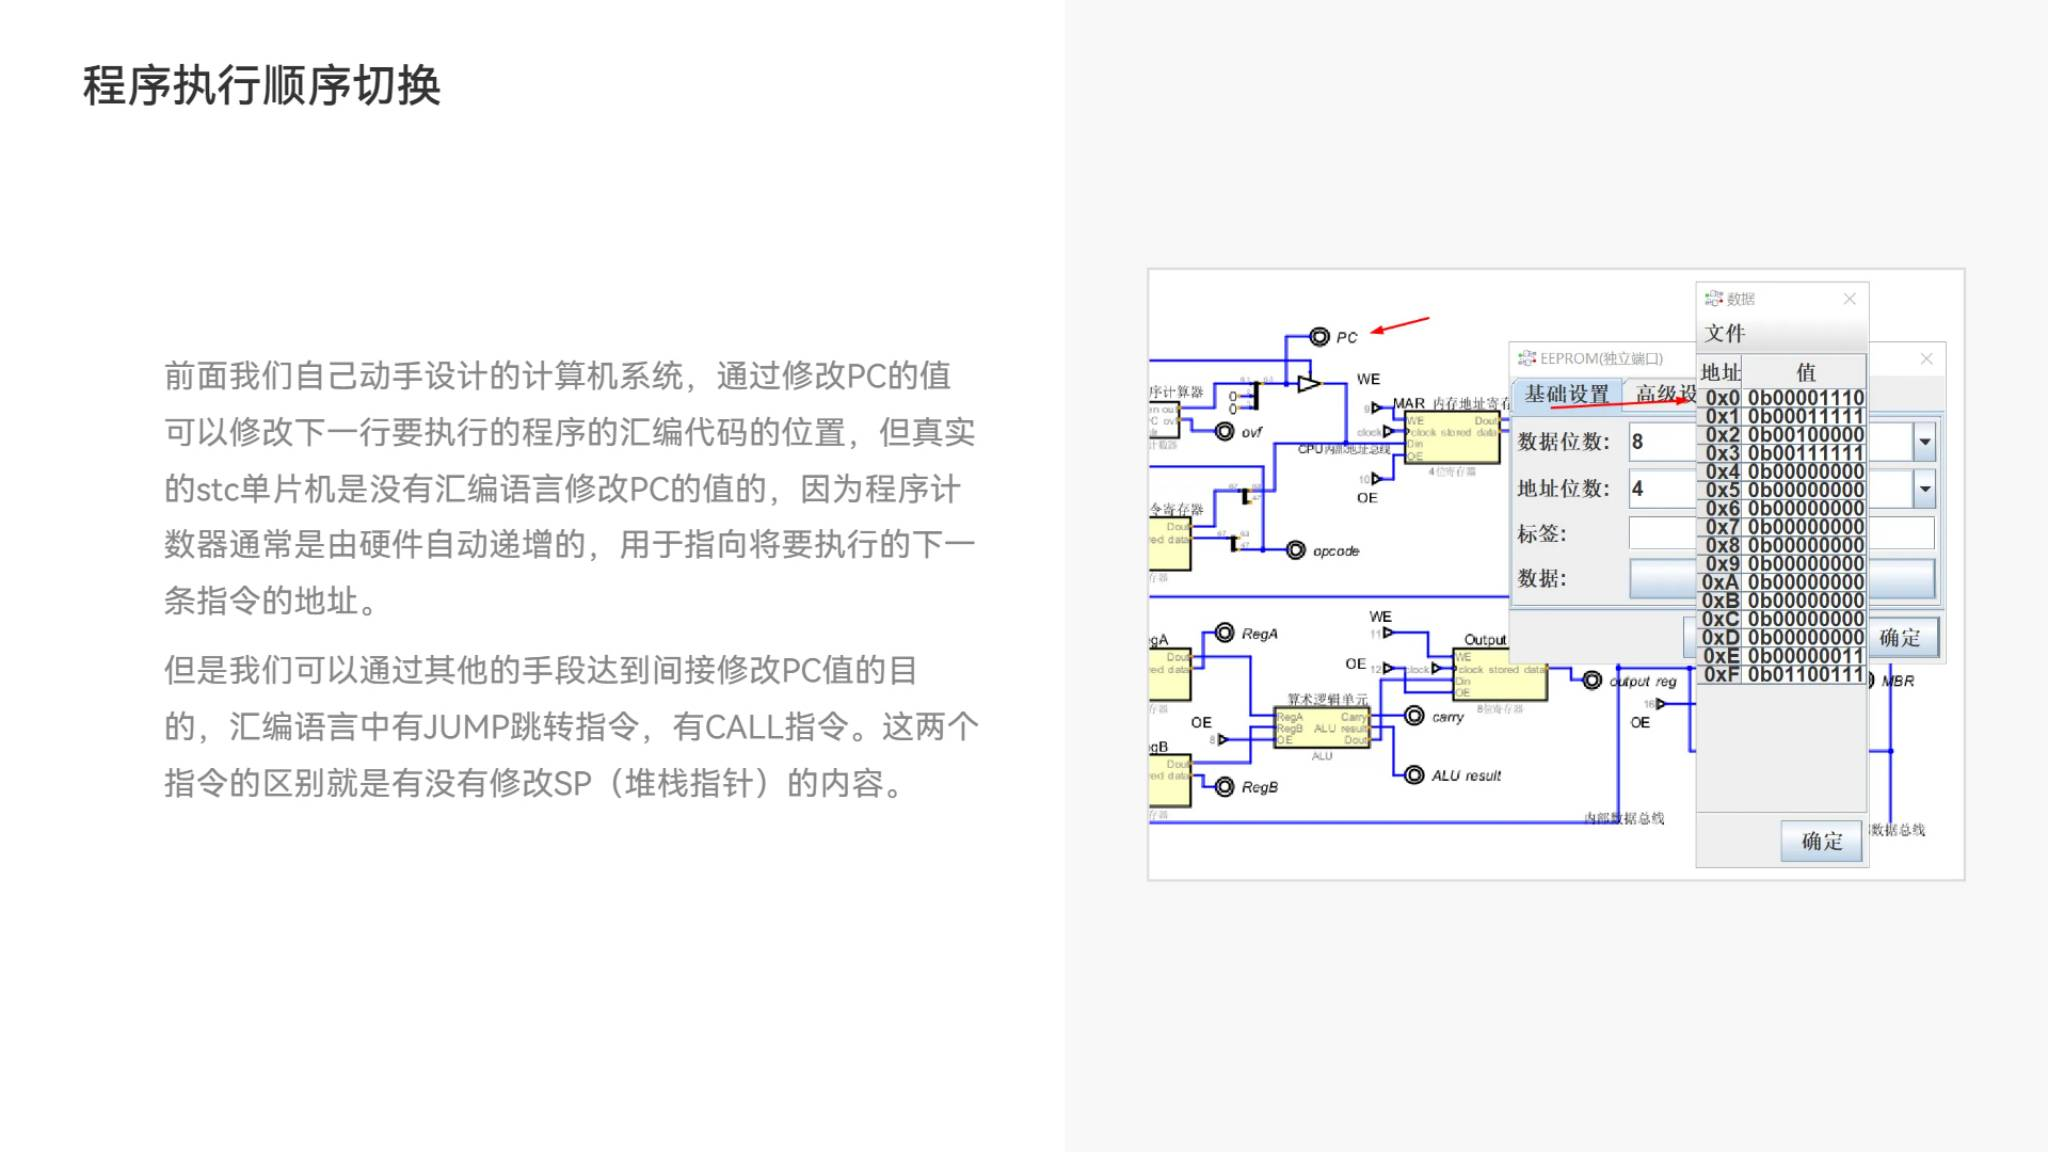

*来源：配套讲义第 16 页，原始在线预览图。*

讲义把前面教学 CPU 的 PC 与真实 STC 的控制转移联系起来：通过跳转、调用等机制改变执行位置，CALL 还涉及栈。

**补充校正：**“不能修改 PC”应理解为不能把它当作普通数据寄存器用 `MOV PC,...` 直接写入，不是程序只能一直顺序执行。跳转、CALL、RET 和中断都会改变控制流。

| 动作 | 改变执行位置 | 通常保存普通返回地址 |
|---|---|---|
| 普通跳转 | 是 | 否 |
| CALL | 是 | 是 |
| RET | 从当前栈恢复位置 | 消耗已保存的返回地址 |

本课程的关键思路是：**让返回指令看到另一份栈里的地址，而不是原调用链里的地址。** 这就把“改变 SP”和“改变程序执行顺序”连接起来。


## 10. 源码怎样声明两组任务栈？

下面是 `os_demo/main.c` 的**源码摘录**，去掉注释并统一空白；宏名保留原文：

```c
#define MAX_TASKS 2
#define MAX_TASK_DEP 32

unsigned char idata task_sp[MAX_TASKS];
unsigned char idata task_stack[MAX_TASKS][MAX_TASK_DEP];
unsigned char task_id;
```

| 名称 | 具体作用 |
|---|---|
| `MAX_TASKS` | 任务个数为 2 |
| `MAX_TASK_DEP` | 每行任务栈分配 32 字节，不能据此断言容量足够 |
| `task_stack[0]` | 任务 0 的 32 字节栈区域 |
| `task_stack[1]` | 任务 1 的 32 字节栈区域 |
| `task_sp[0/1]` | 各任务保存的栈顶地址数值，不是入口地址 |
| `task_id` | 当前选择的任务编号 |

两组栈数组共占 `2×32=64` 字节，两项 SP 共占 2 字节。这里没有把任务状态结构、其他变量和默认栈开销算进去。

**补充理解：**`idata` 是 Keil C51 的存储空间限定词，不是标准 C 关键字。它指定可间接访问的内部 RAM。`data`、`idata`、`xdata`、`code` 在 C51 中具有不同含义，不能只凭变量名更换空间。


## 11. 用包内链接表确定真实地址

以下数值来自包内已有的 `Listings/project.m51`，**只对应该次编译布局**，不是固定的 STC 地址。

```text
I:0009H  tasks
I:0015H  task_stack
I:0055H  task_sp
D:0008H  task_id
D:0081H  SP
C:0190H  task0
C:011DH  task1
```

`I:`、`D:`、`C:` 区分链接表中的空间/符号类型。这里 `D:0081H SP` 是 SFR 符号，不能把所有 `D:` 都简单理解成普通 RAM。

| 对象 | 本次布局 |
|---|---|
| `task_stack[0]` | 内部 RAM `0x15—0x34` |
| `task_stack[1]` | 内部 RAM `0x35—0x54` |
| `task_sp[0]` | 内部 RAM `0x55` |
| `task_sp[1]` | 内部 RAM `0x56` |
| `task0` 入口 | CODE `0x0190` |
| `task1` 入口 | CODE `0x011D` |

32 字节一行，所以第二行首地址为 `0x15+0x20=0x35`。数组行边界不会被硬件 SP 自动检查。

**补充理解：**这个布局把部分可用内部 RAM 分给了数组；链接表只预留了寄存器组 0。若后续使用其他寄存器组或位变量，需要重新检查布局，不能把这些数值硬编码为通用模板。重新编译、改变变量或选项都可能改变地址。


## 12. task_load：构造任务第一次返回的位置

配套源码的实际函数为：

```c
void task_load(unsigned int fn, unsigned char tid){
    task_sp[tid] = task_stack[tid] + 1;
    task_stack[tid][0] = fn & 0xff;
    task_stack[tid][1] = fn >> 8;
}
```

这是**源码摘录**，只统一空白。逐行解释：

1. `task_stack[tid] + 1` 指向第二个字节，把它的内部 RAM 地址保存到 `task_sp[tid]`，令初始 SP 指向顶部。
2. `[0]` 保存函数入口地址的低 8 位。
3. `[1]` 保存高 8 位，位于低字节的高地址一侧。

```text
初始栈：
首地址 base     ：入口低字节
首地址 base + 1 ：入口高字节 ← 初始 SP
```

这相当于准备一份“已经有可返回地址的栈”。第一次 RET 取出这两个字节，便进入任务入口。

**补充理解：**源码把函数地址交给 `unsigned int`，又把 `idata` 指针表达式赋给 `unsigned char`。这是本工程的 C51 特定用法；包内清单证明它在该配置下按目标地址生成了代码，不代表它是可移植的标准 C。不能直接照搬到指针宽度、存储模型或调用约定不同的环境。


## 13. 把实际入口地址拆成两个字节

结合本次链接表，初始化 `task0` 和 `task1` 得到：

| 任务 | 入口地址 | 栈首地址 | `[0]` 低字节 | `[1]` 高字节 | 初始保存的 SP |
|---|---|---|---|---|---|
| 0 | `0x0190` | `0x15` | `0x90`，位于 `0x15` | `0x01`，位于 `0x16` | `0x16` |
| 1 | `0x011D` | `0x35` | `0x1D`，位于 `0x35` | `0x01`，位于 `0x36` | `0x36` |

```text
任务0栈： [0x15:90] [0x16:01] ... [0x34]   task_sp[0]=0x16
任务1栈： [0x35:1D] [0x36:01] ... [0x54]   task_sp[1]=0x36
```

**补充推演：**初始任务 0 执行 RET 后，PC 恢复为 `0x0190`，SP 变为 `0x14`；任务 1 对应为 PC=`0x011D`、SP=`0x34`。此时地址字节已被逻辑弹出，下次压栈从各自首地址开始。

“SP 指向高字节”与“入口低字节放在 `[0]`”必须配套。颠倒字节或让 SP 指向 `[0]`，返回指令就会取到错误的组合。


## 14. main 末尾怎样第一次进入 task0？

配套 `main.c` 的**源码摘录**：

```c
void main(){
    Timer0_init();
    Timer1_Init();
    task_load(task0,0);
    task_load(task1,1);
    task_id = 0;
    SP = task_sp[0];
}
```

从 C 文本看，结尾只写了 SP，没有直接调用 `task0()`。真正的控制转移要看生成指令。

包内 `project.hex` 在本次 CODE 地址 `0x01CD—0x01D2` 的结尾为：

```asm
MOV R0, #055H   ; 定位 task_sp[0]
MOV A, @R0      ; 取出初始保存的 SP
MOV SP, A       ; 使用任务0的初始栈
RET             ; 从这份栈取出 task0 的入口地址
```

对应字节为 `78 55 E6 F5 81 22`；最后的 `22` 是 RET。包内启动代码以跳转进入 main，本例利用 main 的这个返回结尾启动任务。

**结论：**不是 C 语言规定“main 结束就进入任务 0”，而是这个工程的入口、生成代码和预构造返回地址配合产生该效果。换编译器或启动约定，必须重新检查。

本节只解释启动路径；完整源码还提前启用了计时相关功能。更完整的初始化设计需要在任务数据准备好后再允许相关中断，不能仅凭这段课堂演示认定初始化时序已经覆盖全部场景。


## 15. 写 SP 与执行 RET 是两个不同瞬间

以下为**补充推演**，暂不考虑中断和其他寄存器保存。

| 时刻 | 发生什么 | PC 和 SP 的关系 |
|---|---|---|
| 写 `SP=task_sp[0]` | 改变当前栈位置 | PC 仍在执行启动代码 |
| 执行 RET | 从新栈取出地址 | PC 变为任务 0 入口 |
| 执行任务代码 | 使用自己的栈继续运行 | 后续 CALL/PUSH 改变当前 SP |

```text
修改 SP → 当前栈换了
执行 RET → 返回地址来自换后的栈
恢复 PC → 执行位置随之改变
```

这解释了视频 13 的主题“通过修改 SP，来修改调用的函数”。更准确地说，本例改变了**随后返回的目标**，不是把源代码中的普通调用自动替换成另一个函数调用。


## 16. 再次切入任务，要回到中断前还是函数开头？

第一次需要进入任务函数入口；以后通常应回到该任务**上一次让出时的继续位置**。如果每次都重新用入口地址覆盖任务栈，就会反复从头执行。

配套源码中的 `task_switch` 为：

```c
void task_switch(){
    task_sp[task_id] = SP;
    task_id = task_id + 1;
    if(task_id == MAX_TASKS){
        task_id = 0;
    }
    SP = task_sp[task_id];
}
```

这是**源码摘录**。本篇只用它解释返回链；选择算法和上下文保护留给第 03 篇。

在普通函数调用路径中，调用 `task_switch` 时，调用后应继续的位置已经被 CALL 放入当前任务栈。保存 SP 并换到另一任务栈后，本次编译生成的结尾 RET 就从目标栈返回。

```text
A 调用 task_switch
  → A 的继续地址在 A 栈中
  → 保存 A 的 SP
  → 恢复 B 的 SP
  → RET 使用 B 栈：首次进 B 入口，后续回 B 继续位置
```

任务栈最初的两个入口字节在首次弹出后，可以被后续调用的返回地址覆盖。它们不是需要永远保留不变的“任务入口槽”。


## 17. 用现有编译结果追踪一次 A→B→A

下面是**结合包内机器码的简化推演**，忽略中断及其他上下文影响，不是当前设备的运行记录。

包内 `task0` 在 `0x01AE` 用 LCALL 调用 `task_switch`，继续位置为 `0x01B1`；`task1` 的相应调用位于 `0x0140`，继续位置为 `0x0143`。

| 步骤 | 当前操作 | 关键栈与地址 |
|---|---|---|
| 1 | main 使用任务 0 初始栈并 RET | PC=`0x0190`，SP=`0x14` |
| 2 | task0 调用 task_switch | 栈 `0x15` 写 `0xB1`，`0x16` 写 `0x01`；SP=`0x16` |
| 3 | 保存 A 的 SP，换到 B 初始栈 | `task_sp[0]=0x16`，SP=`0x36` |
| 4 | RET 第一次进入 task1 | PC=`0x011D`，SP=`0x34` |
| 5 | task1 调用 task_switch | 栈 `0x35` 写 `0x43`，`0x36` 写 `0x01`；SP=`0x36` |
| 6 | 保存 B 的 SP，恢复 A 的 SP 并 RET | PC=`0x01B1`，SP=`0x14` |

此后恢复 B 的栈，会回到 `0x0143`，而不是重新进入 `0x011D`。

这个过程证明了“换栈能够换继续位置”，但**不证明全部寄存器和临时变量都已被正确保存**。必须把返回地址机制与完整上下文机制分开判断。


## 18. 为什么私有任务栈还不能保证上下文完整？

以下为**补充理解**。

栈指针正确，只说明找到了对应的栈。任务在切换前还可能把临时值放在 ACC、B、R0—R7、DPTR、PSW 等位置；RET 本身不会把它们全部恢复。

此外，Keil C51 的非重入函数可能把参数或局部变量放在寄存器、固定数据区或可覆盖区。包内链接表显示了 SMALL 模型和 overlay 分析，不能套用“所有 C 局部变量都自动在各任务私有栈上”的假设。

| 已经做到 | 尚不能据此推断 |
|---|---|
| 每个任务有一段独立栈区域 | 所有临时数据都已经私有 |
| 保存并恢复 SP | 所有寄存器都已保存恢复 |
| RET 到正确位置 | 继续执行时使用的数值一定正确 |
| 包内已有编译成功清单 | 多任务逻辑经过了完整运行验证 |

从普通调用和从中断进入切换函数时，栈上的帧、编译器保存动作和返回指令要求也可能不同。第 03 篇将继续分析这些约束，本篇不把当前最小示例当作可直接移植的完整内核。


## 19. 32 字节任务栈怎样评估？

源码每个任务分配 32 字节，这是容量选择，**不是“32 层调用”**。

**补充理解：**栈消耗可能包括：

- 每层调用的返回地址，经典普通调用占 2 字节；
- 软件压入的寄存器和临时信息；
- 中断入口及中断处理保存的数据；
- 编译器生成的相关栈操作；
- 多层调用、中断嵌套的最坏情况组合。

初始返回帧使用 2 字节；首次 RET 后这两个字节被逻辑弹出，不能把每次返回帧都累计为永远不释放的空间。

自编预算例子：3 层尚未返回的调用占 6 字节，软件保存占 6 字节，一次中断返回地址占 2 字节，中断额外保存占 4 字节，则当时共占 18 字节。它不是当前程序的实测上限，还需计入实际生成代码和其他可能路径。

本工程任务 0 栈最后一个地址是 `0x34`。如果继续向上压入，可能写入任务 1 栈；任务 1 再越界可能覆盖保存 SP 的数组。硬件不会因为二维数组有 32 列就自动报错。可结合最深调用链、栈填充标记和调试观察估计使用量，但单次测试不能覆盖全部最坏情况。


## 20. 调试时观察什么，怎样判断机制正确？

以下是**补充调试方法**，不是已经执行的测试报告。使用与目标和工具链匹配的模拟器或设备调试环境。

| 观察点 | 应确认的关系 |
|---|---|
| task_load 返回后 | 各任务低/高入口字节及保存 SP 与布局一致 |
| main 改 SP 前后 | SP 改变，PC 仍在启动路径中 |
| main 的 RET 后 | 第一次进入 task0 入口 |
| task_switch 调用刚进入 | 当前栈已含调用后的返回位置 |
| 写入目标 SP 后 | 栈位置属于目标任务，不是源任务 |
| 切换后的 RET | 返回到目标任务的入口或继续位置 |
| 多轮切换 | 保存 SP 未越界，栈未互相覆盖，数据仍正确 |

每次改源码或编译选项，应重新查看链接表与生成指令，再设置断点；不要继续使用本篇旧地址当成固定符号。

| 异常表现 | 优先检查 |
|---|---|
| 首次进入错误地址 | 入口字节顺序、初始 SP、返回指令 |
| 每次都从任务开头执行 | 是否反复重建初始返回帧，是否保存实际继续位置 |
| 返回到正确位置，但数值异常 | 寄存器、PSW、局部变量和覆盖区的上下文 |
| 偶发跳转失控 | 栈越界、嵌套帧、中断与切换入口的约定 |
| 换工具链后失效 | 指针表示、启动代码、函数结尾与内存模型 |


## 21. 一页复习表

| 知识点 | 应能解释 |
|---|---|
| CODE 与 RAM | 任务代码与任务栈不在同一种地址空间 |
| SFR 与高 RAM | 同号地址要按直接/间接等访问方式区分 |
| PC 与 SP | 代码位置与栈顶位置，不能互相代替 |
| 8051 栈方向 | 压栈先加 SP，栈向高地址增长 |
| 普通返回帧 | 低字节在低地址，高字节在顶部 |
| task_stack | 实际的任务栈区域，每行 32 字节 |
| task_sp | 保存各任务 SP 的数组，不是任务入口表 |
| task_load | 构造初始返回地址并设置保存的初始 SP |
| 首次启动 | 该工程 main 的 RET 从任务初始栈进入入口 |
| 后续切换 | 从保存栈返回到上一次调用之后的继续位置 |
| 布局地址 | 来自本次链接结果，重新编译可能变化 |
| 上下文完整性 | 正确返回地址只是其中一部分 |
| 可移植性 | 依赖存储模型、指针、调用和中断约定 |


## 22. 自测与参考答案

1. 为什么任务栈中存了函数地址，不能说函数机器码已被复制进去？
2. 实现高 RAM 的器件上，间接访问 `0x81` 是否就是改 SP？
3. 给首地址 `0x40` 的栈设置空栈 SP，应是 `0x3F` 还是 `0x40`？
4. CALL 保存的是被调用函数入口，还是调用后的继续位置？
5. 源码的初始化函数到底叫 loadtask 还是 task_load？
6. task0 入口 `0x0190` 放到 `[0]`、`[1]` 分别是什么？初始 SP 指向哪项？
7. 本次任务 1 栈首地址和初始保存 SP 分别是多少？
8. 修改 SP 后，是否立即跳到 SP 所表示的地址执行？
9. task0 第一次让出后再恢复，为什么可以继续而不是从头运行？
10. 有两个任务私有栈，是否就保证所有 C 临时变量和寄存器都私有？
11. 栈只有 32 字节时，是否允许 32 层普通嵌套调用？
12. 包内已有 hex 文件，是否表示本篇在当前设备运行验证过？

### 参考答案

1. 放进去的是入口地址两个字节，指令仍在程序空间；这准备的是返回目标。
2. 不是。经典直接寻址的 SFR SP 与间接访问的高内部 RAM 要区分。
3. `0x3F`，因为第一次压入会先加 SP，再写 `0x40`。
4. 继续位置，普通 RET 应回到调用之后。
5. 视频标题写 loadtask；实际配套源码写 `task_load`。
6. `[0]=0x90`、`[1]=0x01`，初始 SP 指向 `[1]`。
7. 首地址 `0x35`，初始保存 SP=`0x36`，仅对应包内该次布局。
8. 不会。后续 RET 等机制从新栈取出地址，再改变 PC。
9. CALL 已把继续位置保存到任务栈，保存和恢复 SP 后可由 RET 取回。
10. 不保证。还需分析寄存器保存、非重入变量及覆盖区等。
11. 不允许这样推断。每层普通返回地址已有 2 字节，还要给其他保存和中断留空间。
12. 没有。本篇只静态核对包内源码和已有编译结果，没有重新编译或硬件验证。

### 自编计算练习

某任务初始栈首地址为 `0x60`，任务入口 `0x2A35`。构造两字节初始帧时，RAM `0x60`、`0x61` 保存什么？初始 SP 和首次 RET 后 SP 是多少？

**答案：**`[0x60]=0x35`、`[0x61]=0x2A`；初始 SP=`0x61`；RET 后 PC=`0x2A35`、SP=`0x5F`。这是按本篇普通返回规则推演的示例。


## 23. 课程对应、来源与下一篇

| 本篇内容 | 对应主题 | 证据范围 |
|---|---|---|
| 内存区域、代码与数据、执行顺序 | 视频 09—10 | 已核对讲义第 14—16 页，并补充访问方式及校正 |
| 两组任务 SP 与栈 | 视频 11 | `main.c` 的声明、`project.m51` 的实际布局 |
| 初始栈与 task_load | 视频 12 | 源码函数及包内编译清单 |
| 修改 SP 后由 RET 改变执行位置 | 视频 13 | main、task_switch 摘录，以及 hex 中的返回结尾 |
| 栈容量、寄存器保护与调试方法 | 扩展理解 | 补充说明，不作为视频逐字内容 |

资料来源：[《自己动手写嵌入式操作系统》课程网盘](https://pan.baidu.com/s/1BaPETt4F3Xnew179lHT4DA?pwd=9988)，提取码 `9988`。讲义为 `ppt/自己动手写嵌入式操作系统.pdf`，共 16 页；配套代码为 `代码/os_demo.zip`。本篇需要的原图、代码片段和地址表已包含在笔记中。

| 编号 | 笔记 | 对应视频 |
|---|---|---|
| 01 | [操作系统基础、多任务与资源调度](01-操作系统基础、多任务与资源调度.ipynb) | 01—08 |
| 02 | STC内存、任务堆栈与任务切换原理 | 09—13 |
| 03 | 任务调度器与上下文保护 | 14—15 |
| 04 | 多任务外设访问与延时问题 | 16—17 |
| 05 | sleep实现与定时时间片轮转 | 18—19 |

下一篇继续回答：任务编号怎样轮转、普通调用与中断切换有什么不同、为什么回到了正确代码位置却可能使用错误数值，以及怎样检查上下文保护。
